# Modello di regime di Super-Eddington


MODELLO SUPER-EDDINGTON CON FLUSSO LOCALE LIMITATO

MBH                    = 1.0000e+08 Msun
eta                     = 0.0830

mdot input              = 5.0000
mdot crit               = 0.3000

Ledd                    = 1.3000e+46 erg/s
Ldisk SS input          = 6.5000e+46 erg/s
Ldisk SS input / Ledd   = 5.0000

Mdot                    = 8.7135e+26 g/s

Tmax SS                 = 2.1102e+05 K
Tmax SE                 = 2.0236e+05 K


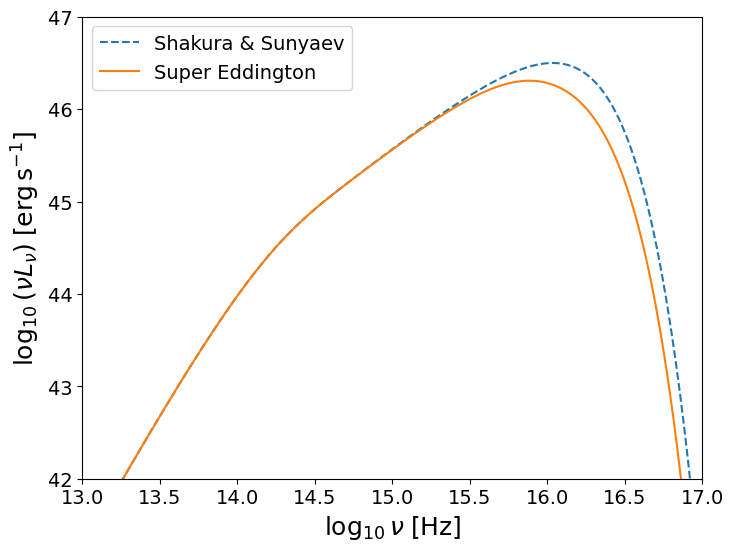

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# =============================================================================
# COSTANTI
# =============================================================================

c = 2.99792458e10          # velocità della luce [cm/s]
G = 6.67430e-8             # costante gravitazionale [cm^3 g^-1 s^-2]
h = 6.62607015e-27         # costante di Planck [erg s]
kB = 1.380649e-16          # costante di Boltzmann [erg/K]
sigma = 5.670374419e-5     # Stefan-Boltzmann [erg cm^-2 s^-1 K^-4]                  
Msun = 1.98847e33          # massa solare [g]


# =============================================================================
# PARAMETRI DEL BUCO NERO
# =============================================================================

MBH = 1e8 * Msun
#MBH = 3.339e6 * Msun
eta = 0.083
Ledd = 1.3e38 * (MBH / Msun)   #erg/s
Rs = 2 * G * MBH / c**2
Rin = 3 * Rs
Rout = 3000 * Rs

# =============================================================================
# INPUT: TASSO DI ACCRESCIMENTO 
# =============================================================================
#mdot = 1  #SS=SE
mdot= 5
#mdot=2.

mdot_crit = 0.30  #inutile ora

# Luminosità che avrebbe il normale SS con questo mdot
Ldisk_SS_input = mdot * Ledd
# Tasso di accrescimento fisico
Mdot = Ldisk_SS_input / (eta * c**2)      


# =============================================================================
# GRIGLIA RADIALE
# =============================================================================

Nr = 4000
R = np.logspace(np.log10(Rin),np.log10(Rout),Nr)

# =============================================================================
# FATTORE DI BORDO SHAKURA-SUNYAEV
# =============================================================================

f = 1.0 - np.sqrt(Rin / R)
f = np.clip(f,0.0,None)

# =============================================================================
# FLUSSO e TEMPERATURA DI SHAKURA & SUNYAEV
# =============================================================================

F_SS = (3* G* MBH* Mdot/(8* np.pi* R**3)*f)
T_SS = (F_SS/sigma)**0.25

# =============================================================================
# FLUSSO e TEMPERATURA DI EDDINGTON
# =============================================================================

F_Edd = (Ledd/(4*np.pi*R**2))
T_Edd = (F_Edd/sigma)**0.25


# =============================================================================
# MODELLO SUPER-EDDINGTON
# =============================================================================

F_SE = np.minimum(F_SS,F_Edd)


# temperatura effettiva finale
T_SE = (F_SE/sigma)**0.25


# =============================================================================
# IDENTIFICAZIONE DELLA REGIONE LIMITATA DA EDDINGTON
# =============================================================================

mask_Edd = F_SS > F_Edd  # la regione limitata da Eddington ha F_SS > F_Edd

if np.any(mask_Edd):  # se ci sono regioni limitate da Eddington 
    indices_Edd = np.where(mask_Edd)[0]  
    R_Edd_inner = R[indices_Edd[0]]  # la regione limitata da Eddington ha un estremo interno
    R_Edd_outer = R[indices_Edd[-1]]  # la regione limitata da Eddington ha un estremo esterno

else:  # se non ci sono regioni limitate da Eddington
    R_Edd_inner = None   # la regione limitata da Eddington non esiste
    R_Edd_outer = None


# =============================================================================
# INFORMAZIONI SUL MODELLO
# =============================================================================

print()
print("=" * 90)
print("MODELLO SUPER-EDDINGTON CON FLUSSO LOCALE LIMITATO")
print("=" * 90)

print()

print(f"MBH                    = {MBH/Msun:.4e} Msun")
print(f"eta                     = {eta:.4f}")

print()

print(f"mdot input              = {mdot:.4f}")
print(f"mdot crit               = {mdot_crit:.4f}")

print()

print(f"Ledd                    = {Ledd:.4e} erg/s")
print(f"Ldisk SS input          = {Ldisk_SS_input:.4e} erg/s")
print(f"Ldisk SS input / Ledd   = {Ldisk_SS_input/Ledd:.4f}")

print()

print(f"Mdot                    = {Mdot:.4e} g/s")

print()

print(f"Tmax SS                 = {np.max(T_SS):.4e} K")
print(f"Tmax SE                 = {np.max(T_SE):.4e} K")


"""
if R_Edd_inner is not None:

    print()
    print("REGIONE LIMITATA DAL FLUSSO DI EDDINGTON")

    print(
        f"R_Edd_inner             = "
        f"{R_Edd_inner/Rs:.4f} Rs"
    )

    print(
        f"R_Edd_outer             = "
        f"{R_Edd_outer/Rs:.4f} Rs"
    )

else:

    print()
    print("Nessuna regione supera il flusso locale di Eddington.")
"""

# =============================================================================
# VETTORE DELLE FREQUENZE
# =============================================================================

Nnu = 800
nu = np.logspace(13,17,Nnu)

# =============================================================================
# FUNZIONE PER CALCOLARE L_nu   (esattamente come nel caso di Shakura & Sunyaev)
# =============================================================================

def calculate_Lnu(T_profile): # T_profile = temperatura per ogni raggio, calcolo Bnu per ogni frequenza e ogni raggio e poi integro su R
    # matrice:righe   = frequenze, colonne = raggi
    Bnu = np.zeros((Nnu, Nr))
    for j in range(Nr):
        Tj = T_profile[j]
        # a Rin, nel modello SS, T può essere zero
        if Tj <= 0.0:
            continue

        x = (h*nu/(kB*Tj))

        # evito overflow numerici
        x = np.clip(x,1e-12,700.0)

        # funzione di Planck
        Bnu[:, j] = (2*h*nu**3/c**2) / np.expm1(x)  


    integrand = (R[None, :]*Bnu)
    I_nu = np.trapezoid(integrand,R,axis=1)
    Lnu = (4*np.pi**2*I_nu)
    return Lnu


# =============================================================================
# SPETTRI
# =============================================================================

Lnu_SS = calculate_Lnu(T_SS)
Lnu_SE = calculate_Lnu(T_SE)

nuLnu_SS = (nu*Lnu_SS)
nuLnu_SE = (nu*Lnu_SE)

# =============================================================================
# PLOT FINALE
# =============================================================================

plt.figure(figsize=(8, 6))

# normale Shakura-Sunyaev
plt.plot(np.log10(nu),np.log10(nuLnu_SS),
    linestyle="--",
    label="Shakura & Sunyaev")

# modello super Eddington
plt.plot(np.log10(nu),np.log10(nuLnu_SE),
    label=rf'Super Eddington')

plt.xlabel(r'$\log_{10}\nu\;[\mathrm{Hz}]$',fontsize=18)
plt.ylabel(r'$\log_{10}(\nu L_\nu)'r'\;[\mathrm{erg\,s^{-1}}]$',fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlim(13,17)
plt.ylim(42,47)
plt.legend(fontsize=14)
plt.show()

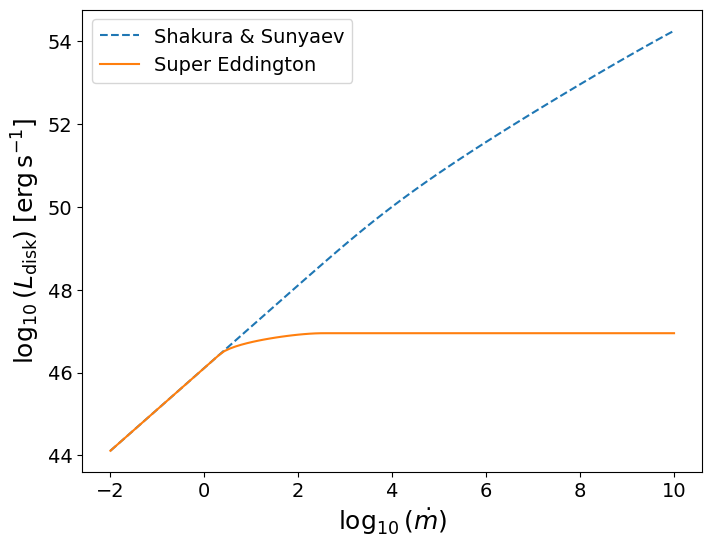

In [26]:
# =============================================================================
# PLOT DELL'INTEGRALE DI L_NU IN FUNZIONE DEL TASSO DI ACCRESCIMENTO
# =============================================================================
mdot_values = np.logspace(-2, 10, 100)
Ldisk_SS_values = []
Ldisk_SE_values = []

for mdot_i in mdot_values:
    Ldisk_SS_input_i = mdot_i * Ledd
    Mdot_i = Ldisk_SS_input_i / (eta * c**2)


    F_SS_i = (3 * G * MBH * Mdot_i/ (8 * np.pi * R**3)* f)
    T_SS_i = (F_SS_i / sigma)**0.25

    F_SE_i = np.minimum(F_SS_i, F_Edd)
    T_SE_i = (F_SE_i / sigma)**0.25


    # -------------------------------------------------------------------------
    # SPETTRI
    # -------------------------------------------------------------------------

    Lnu_SS_i = calculate_Lnu(T_SS_i)
    Lnu_SE_i = calculate_Lnu(T_SE_i)


    # -------------------------------------------------------------------------
    # INTEGRALE SU FREQUENZA
    # -------------------------------------------------------------------------

    Ldisk_SS_i = np.trapezoid(Lnu_SS_i, nu)
    Ldisk_SE_i = np.trapezoid(Lnu_SE_i, nu)

    Ldisk_SS_values.append(Ldisk_SS_i)
    Ldisk_SE_values.append(Ldisk_SE_i)


# trasformo in array
Ldisk_SS_values = np.array(Ldisk_SS_values)
Ldisk_SE_values = np.array(Ldisk_SE_values)


# =============================================================================
# PLOT
# =============================================================================

plt.figure(figsize=(8, 6))

plt.plot(
    np.log10(mdot_values),
    np.log10(Ldisk_SS_values),
    linestyle="--",
    label="Shakura & Sunyaev"
)

plt.plot(
    np.log10(mdot_values),
    np.log10(Ldisk_SE_values),
    label="Super Eddington"
)



plt.xlabel(
    r"$\log_{10}(\dot{m})$",
    fontsize=18
)

plt.ylabel(
    r"$\log_{10}(L_{\rm disk})\;[\mathrm{erg\,s^{-1}}]$",
    fontsize=18
)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=14)
plt.show()



mdot = 0.1
Nessuna regione limitata da Eddington

mdot = 0.3
Nessuna regione limitata da Eddington

mdot = 1
Nessuna regione limitata da Eddington

mdot = 2
Nessuna regione limitata da Eddington

mdot = 5
Regione Eddington = 3.535 - 31.162 Rs

mdot = 100
Regione Eddington = 3.021 - 848.661 Rs


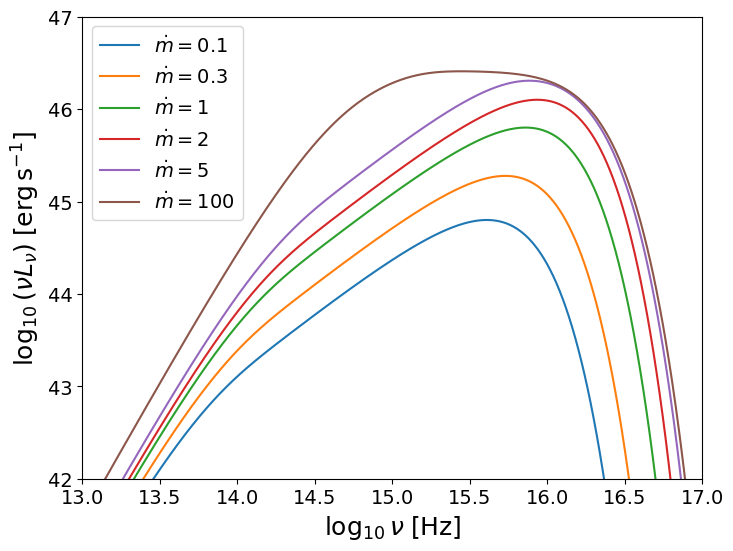

In [28]:
# =============================================================================
# CONFRONTO DI MDOT DIFFERENTI, COME IMPATTANO SU L'EMISSIONE (MI ASPETTO CHE SPETTRO DIVENTI PIù PIATTO)
# =============================================================================

MBH = 1e8 * Msun
#MBH =3.339e6 * Msun

eta = 0.083
Rs = 2 * G * MBH / c**2
Rin = 3 * Rs
Rout = 3000 * Rs
Ledd = 1.3e38 * (MBH / Msun)   #erg/s
mdot_crit = 0.30

#mdot_values = [0.5,2,10]
mdot_values = [0.1, 0.3, 1, 2, 5, 100]                                                                           

# =============================================================================
# FUNZIONE PER COSTRUIRE LO SPETTRO SUPER-EDDINGTON
# =============================================================================

def calculate_SE_spectrum(mdot_value):   # funzione che calcola lo spettro super-eddington per un dato valore di mdot_value

    Ldisk_SS_input = (mdot_value*Ledd )  # luminosità che avrebbe il normale Shakura-Sunyaev con questo mdot_value
    Mdot_value = (Ldisk_SS_input/(eta * c**2))  # tasso di accrescimento fisico corrispondente a questo mdot_value
    F_SS_value = (3*G*MBH*Mdot_value/(8*np.pi*R**3)*f)   # flusso di Shakura-Sunyaev per questo tasso di accrescimento



    F_SE_value = np.minimum( F_SS_value,F_Edd)


    T_SE_value = (F_SE_value/sigma)**0.25

    Bnu_value = np.zeros(
        (Nnu, Nr) )


    for j in range(Nr):
        Tj = T_SE_value[j]

        if Tj <= 0.0:
            continue

        x = (h*nu/ ( kB*Tj))
        x = np.clip(x,1e-12,700.0)

        Bnu_value[:, j] = (2*h*nu**3/c**2) / np.expm1(x)


    integrand_value = (R[None, :]*Bnu_value)
    I_nu_value = np.trapezoid(integrand_value,R,axis=1)
    Lnu_value = (4*np.pi**2*I_nu_value)

    nuLnu_value = (nu*Lnu_value)




    # Regione limitata da Eddington
    mask_Edd_value = (F_SS_value>F_Edd)

    if np.any(mask_Edd_value):
        indices = np.where(mask_Edd_value)[0]
        R_inner_value = (R[indices[0]]/Rs )
        R_outer_value = (R[indices[-1]]/Rs)

    else:
        R_inner_value = None
        R_outer_value = None

    return (
        nuLnu_value,
        R_inner_value,
        R_outer_value)


# =============================================================================
# PLOT DEI TRE MODELLI
# =============================================================================

plt.figure(figsize=(8, 6))

for mdot_value in mdot_values:
    (nuLnu_value,R_inner_value,R_outer_value ) = calculate_SE_spectrum(mdot_value)

    plt.plot(
        np.log10(nu),
        np.log10(nuLnu_value),
        label=rf'$\dot{{m}}={mdot_value:g}$'
    )



    print()
    print("=" * 70)

    print(
        f"mdot = {mdot_value:g}"
    )


    if R_inner_value is not None:

        print(
            f"Regione Eddington = "
            f"{R_inner_value:.3f} - "
            f"{R_outer_value:.3f} Rs"
        )

    else:

        print(
            "Nessuna regione limitata da Eddington"
        )


# =============================================================================
# GRAFICO
# =============================================================================

plt.xlabel(
    r'$\log_{10}\nu\;[\mathrm{Hz}]$', 
    fontsize=18)

plt.ylabel(
    r'$\log_{10}(\nu L_\nu)'
    r'\;[\mathrm{erg\,s^{-1}}]$',
    fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlim(13,17)
plt.ylim( 42, 47)
plt.legend(fontsize=14)
plt.show()